# NG20 v2.0 "vanilla" noise model in ATLAS

DM GP + **chromatic GP** (`chrom`) + **chromatic quadratic** (`cquad`, the marginalised CM0/CM1/CM2 of enterprise `chrom_quad`) + **time-domain solar-wind GP** (`sw`, port of PINT `TimeDomainSWNoise`), with the chromatic index shared by `chrom` and `cquad`.

Follows `ChromaticNoise.ipynb`. The two new data-preparation steps are:

1. **Solar-wind geometry per pulsar** (Section 2) -- the `sw` block needs, for every TOA, the DM that a 1 cm$^{-3}$ solar wind at 1 AU would produce. Computed with PINT (exact, needs the JPL ephemeris) or with an analytic Sun position (approximate fallback).
2. **`TDSW*` settings from the par files** (Section 3) -- kernel, node spacing or explicit `TDSWNODE_` nodes (this is how Bayesian-block edges reach the GP), and `TDSWLOGSIG`, turned into the `sw_kwargs` ATLAS takes.

In [1]:
import sys
import glob
import json
import os
import shutil
from pathlib import Path
from functools import partial

import numpy as np
import jax.numpy as jnp
import jax.random as jrandom
import jax

sys.path.append('/data/taylor_group/Nima/AtlasNG20/')
sys.path.append('../')
from ATLAS.data import PTA_Data
from ATLAS.model_builder import ModelBuilder
from ATLAS.psd_functions import powerlaw, hd_orf
from ATLAS.model import model_maker
from ATLAS.pulsar import PulsarDataLoader
from ATLAS.signals.factorized.chromatic import (
    sw_geometry_from_pint, align_to_toas, read_tdsw_par, make_interpolation_basis)

import tqdm_joblib
from enterprise.pulsar import Pulsar
from joblib import Parallel, delayed
from tqdm.auto import trange
import pickle

import numpyro
from numpyro.infer import MCMC, NUTS
%load_ext autoreload
%autoreload 2

libstempo not installed. PINT or libstempo are required to use par and tim files.


In [2]:
AU_PC = 4.84813681109536e-06   # 1 AU in pc

In [3]:
import matplotlib.pyplot as plt
plt.style.use('default')
def figsize(scale, wc = 1, hc = 1):
    fig_width_pt = 513.17 #469.755                  # Get this from LaTeX using \the\textwidth
    inches_per_pt = 1.0/72.27                       # Convert pt to inch
    golden_mean = (np.sqrt(5.0)-1.0)/2.0            # Aesthetic ratio (you could change this)
    fig_width = fig_width_pt*inches_per_pt*scale    # width in inches
    fig_height = fig_width*golden_mean              # height in inches
    fig_size = [wc * fig_width,hc * fig_height]
    return fig_size
plt.rcParams.update(plt.rcParamsDefault)

params = {#'backend': 'pdf',
        'axes.labelsize': 18,
        'lines.markersize': 4,
        'font.size': 10,
        'xtick.major.size':6,
        "xtick.top": True,
        "ytick.right": True,
        "xtick.minor.visible": True,
        "xtick.major.top": True, 
        "xtick.minor.top": True,
        "ytick.minor.visible": True, 
        "ytick.major.right": True, 
        "ytick.minor.right": True,
        "ytick.direction": "in",
        "xtick.direction": "in",
        'xtick.minor.size':3,  
        'ytick.major.size':6,
        'ytick.minor.size':3, 
        'xtick.major.width':0.5,
        'ytick.major.width':0.5,
        'xtick.minor.width':0.5,
        'ytick.minor.width':0.5,
        'lines.markeredgewidth':1,
        'axes.linewidth':1.2,
        'legend.fontsize': 7,
        'xtick.labelsize': 14,
        'ytick.labelsize': 14,
        'savefig.dpi':200,
        'path.simplify':True,
        'font.family': 'serif',
        'font.serif':'Times',
        # "text.usetex": True,
        #'text.latex.preamble': [r'\usepackage{amsmath}'],
        'text.usetex':False,
        'figure.figsize': figsize(0.5, 1, 1)}
plt.rcParams.update(params)
plt.rcParams['font.family'] = 'STIXGeneral'  # Closely matches Computer Modern
plt.rcParams['mathtext.fontset'] = 'stix'    # Use STIX for math

# Loading Data

In [4]:
parfiles = sorted(glob.glob('/data/taylor_group/Nima/NG15_CNM/*.par'))
timfiles = sorted(glob.glob('/data/taylor_group/Nima/NG15_CNM/*.tim'))
len(parfiles), len(timfiles)

(68, 68)

In [5]:
# def doit(pidx):
#     return Pulsar(parfiles[pidx], timfiles[pidx], sort=False, drop_pintpsr=False, 
#                   ephem='DE440', timing_package='PINT')
# with tqdm_joblib.tqdm_joblib(desc="PINT Loading...", total=len(parfiles)) as progress_bar:
#     psrs = Parallel(n_jobs=-1)(delayed(doit)(i) for i in range(len(parfiles)))

In [6]:
# savedir = '/data/taylor_group/Nima/AtlasNG20/datasets/NG15_CNM/'
# for pidx in trange(len(psrs)):
#     np.savez_compressed(savedir + f'{psrs[pidx].name}', **psrs[pidx].__dict__)
#     # print(psrs[pidx].__dict__)
# with open('/data/taylor_group/Nima/AtlasNG20/datasets/NG15_CNM/psrs.pkl', 'wb') as fout:
#     pickle.dump(psrs, fout)

In [7]:
# paths = sorted(glob.glob(str(DATA_DIR / 'ATLAS_pulsar' / '*.npz')))
# psrs = [PulsarDataLoader(**np.load(p, allow_pickle=True)) for p in paths[:NPSR]]
# [str(p.name) for p in psrs]
with open('/data/taylor_group/Nima/AtlasNG20/datasets/NG15_CNM/psrs.pkl', 'rb') as fin:
    psrs = pickle.load(fin)

In [8]:
with open('/data/taylor_group/Nima/Atlas/datasets/NG15/v1p1_wn_dict.json', 'r') as fin:
    noise_dict = json.load(fin)

data = PTA_Data(psrs,
                num_gwb_bins = 14,
                num_irn_bins = 30,
                num_dm_bins = 30,          
                linear_timing = True,
                marg_timing = False,
                noise_dict = noise_dict,
                dm_ref_freq = 1400)        # also the reference frequency of `chrom` / `cquad`
m = ModelBuilder(data = data)

# White Noise

In [9]:
wn = m.make_white_noise(stabilize_TNT = False)
wn_lower_bound, wn_upper_bound = wn.get_prior_bounds()
wn_fixed = wn.params_dict_to_vector(data.noise_dict)

Constructing the white noise cov matrix for B1855+09:   0%|                                                                                                         | 0/68 [00:00<?, ?it/s]

Constructing the white noise cov matrix for J2322+2057: 100%|██████████████████████████████████████████████████████████████████████████████████████████████| 68/68 [00:04<00:00, 13.68it/s]


# SW Geometry, $G(t_i)$, Values per TOA

In [10]:
sw_geometry = [sw_geometry_from_pint(psr.model, psr.pint_toas) for psr in psrs] # This is a wrapper for PINT's `model.solar_wind_geometry`

In [11]:
sw_geometry[0].shape, psrs[0].toas.shape

((7758,), (7758,))

# Time domain SW  settings from the par files (`sw_kwargs`)

PINT stores the time-domain SW model in the par file:

| par file | meaning | ATLAS `TimeDomainSolarWind` kwarg |
|---|---|---|
| `TDSWKERNEL` | `RIDGE` / `SQEXP` / `MATERN` / `QUASI_PERIODIC` | `kernel` |
| `TDSWDT` | uniform node spacing [d] | `dt_days` |
| `TDSWNODE_nnnn` | explicit nodes [MJD] -- **Bayesian-block edges** | `nodes_mjd` |
| `TDSWINTERP_KIND` | interpolation | `interp_kind` |
| `TDSWLOGELL`, `TDSWNU`, `TDSWLOGGAMP`, `TDSWLOGP` | kernel shape (held fixed) | `log10_ell`, `nu`, `log10_gam_p`, `log10_p` |
| `TDSWLOGSIG` | amplitude, log10 cm$^{-3}$ | sampled as `<psr>_sw_log10_amp` (or `fixed_log10_sigma`) |

`read_tdsw_par` reads these; every kwarg accepts a per-pulsar list or `{psr: value}` dict.

In [12]:
tdsw = {str(psrs[pidx].name): read_tdsw_par(parfiles[pidx]) for pidx in range(len(psrs))} # reads the par file and looks for info on time domain solar-wind
                                                                                          # see the cell below for what I mean by 'info'!

In [13]:
sw_kwargs = dict(
    kernel      = [tdsw[n]['kernel'] for n in data.psr_names],
    dt_days     = [tdsw[n]['dt_days'] for n in data.psr_names],
    nodes_mjd   = {n: tdsw[n]['nodes_mjd'] for n in data.psr_names},   # None -> TDSWDT grid
    interp_kind = tdsw[data.psr_names[0]]['interp_kind'],
    log10_ell   = [tdsw[n]['log10_ell'] for n in data.psr_names],
    nu          = [tdsw[n]['nu'] for n in data.psr_names],
    log10_gam_p = [tdsw[n]['log10_gam_p'] for n in data.psr_names],
    log10_p     = [tdsw[n]['log10_p'] for n in data.psr_names],
    # sw_kwargs['fixed_log10_sigma'] = tdsw[names[0]]['log10_sigma']
    lower_bound_psd = (-3.0,),     # prior on log10 sigma [cm^-3]
    upper_bound_psd = (2.0,),
)
# To hold the amplitude at the par-file value instead of sampling it (one value
# for all pulsars): sw_kwargs['fixed_log10_sigma'] = tdsw[names[0]]['log10_sigma']

# Red Noise

The chromatic blocks MUST be separated (so use `;`). List them after `dm`, in this order:

    unc+cor->unc ; dm, chrom, cquad, sw

* `chrom` -- Fourier GP $\times (1400/\nu)^{\chi}$, any ATLAS PSD (power law here).
* `cquad` -- $(t-t_\mathrm{mid})^k (1400/\nu)^{\chi}$, $k=0,1,2$, unit-norm columns, prior s.d. $10^{\texttt{cquad\_log10\_amp}}$ s (effectively flat). With `cquad_project_timing=True` the timing-model column space is projected out first. No sampled parameters. In the par file CM0/CM1/CM2 stay frozen; this block marginalises them.
* `sw` -- the time-domain SW GP, already built above

`chrom_index` sets the reference $\chi$ for both chromatic blocks (scalar, list, or `{psr: chi}` -- e.g. noise-budget / NG15 values). It is either held fixed or sampled (Section 7).

In [14]:
rn = m.make_red_noise("ltm|unc+cor->unc ; dm, chrom, cquad, sw",
                use_pulsar_tspan = False,
                irn_psd_function = partial(powerlaw),
                gwb_psd_function = partial(powerlaw),
                orf_function = hd_orf,
                irn_lower_bound_psd = jnp.array([-18, 0.]),
                irn_upper_bound_psd = jnp.array([-11, 7.]),
                gwb_lower_bound_psd = jnp.array([-18, 0]),
                gwb_upper_bound_psd = jnp.array([-11, 7]),

                #######################################
                dm_psd_function = partial(powerlaw),
                dm_lower_bound_psd = jnp.array([-18, 0]),
                dm_upper_bound_psd = jnp.array([-11, 7]),

                #######################################
                chrom_psd_function = partial(powerlaw),
                chrom_lower_bound_psd = jnp.array([-18, 0]),
                chrom_upper_bound_psd = jnp.array([-11, 7]),
                num_chrom_bins = 30,
                chrom_index = 4.0,

                #######################################
                cquad_log10_amp = 0.0,
                cquad_project_timing = True,

                #######################################
                sw_geometry = sw_geometry,
                sw_kwargs = sw_kwargs,
                )

In [15]:
rn.get_Fmat_concat.shape # damn you chromatic noise modeling!
                         # there has to be a better way to marginalize over all this.

(698037, 400)

In [16]:
param_names = rn.model.get_param_names()
for p in param_names:
    if data.psr_names[0] in p:
        print(p)

B1855+09_irn_log10_A
B1855+09_irn_gamma
B1855+09_dm_log10_A
B1855+09_dm_gamma
B1855+09_chrom_log10_A
B1855+09_chrom_gamma
B1855+09_sw_log10_amp


In [17]:
helpers = rn.get_helpers(reff = jnp.concat(data.raw_residuals), white_noise_params = wn_fixed)
x0 = rn.model.make_initial_guess(jrandom.key(0))
z0 = jnp.zeros((data.npsrs, rn.nmodes))
lp, _ = rn.lnposterior_reparam(helpers, x0, z0)
lp

Array(8704020.04573156, dtype=float64)

In [18]:
%timeit rn.lnposterior_reparam(helpers, x0, z0)

2.22 ms ± 252 ns per loop (mean ± std. dev. of 7 runs, 100 loops each)


# Sampling with the chromatic index fixed (at `chrom_index`)

In [21]:
mcmc_fixed = MCMC(NUTS(model=model_maker, target_accept_prob=0.8, max_tree_depth=10),
                  num_warmup=500, num_samples=4000, num_chains=1)
mcmc_fixed.run(jrandom.key(170817),
               extra_fields=("~z.z_a",),
               raw_residuals = jnp.concat(data.raw_residuals),
               super_sig = rn,
               vary_white = False,
               helpers = helpers,
               save_red_coeff = False,
               marg_over_non_gwb = False)

sample: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 4500/4500 [1:00:58<00:00,  1.23it/s, 127 steps of size 3.29e-02. acc. prob=0.92]


# Sampling the shared chromatic index

`varied_chrom_gp_index=True` samples one $\chi$ per pulsar, `chrom_gp_index ~ U(chrom_gp_index_bounds)`, and re-indexes `chrom` **and** `cquad` together (the quadratic is rebuilt, re-normalised and re-projected each step) -- the coupled index of enterprise `chrom_quad`.

The T-matrix now changes every step, so the helpers are rebuilt inside the model. White noise can stay fixed: pass `fixed_white_noise_params` instead of pre-built `helpers`. (Use `vary_white=True` with `wn_lower_bound/wn_upper_bound` to sample it too.)

In [22]:
# mcmc_idx = MCMC(NUTS(model=model_maker, target_accept_prob=0.8, max_tree_depth=10),
#                 num_warmup=500, num_samples=4000, num_chains=1,
#                 # jit_model_args=True
#                 )
# mcmc_idx.run(jrandom.key(170818),
#              extra_fields=("~z.z_a",),
#              raw_residuals = jnp.concat(data.raw_residuals),
#              super_sig = rn,
#              vary_white = False,
#              fixed_white_noise_params = wn_fixed,
#              varied_chrom_gp_index = True,
#              red_noise_basis = rn.get_Fmat_concat,
#              chrom_gp_index_bounds = (0.0, 7.0),
#              save_red_coeff = False,
#              marg_over_non_gwb = False)

# 8. Results

In [25]:
gen_samps = mcmc_fixed.get_samples()['red_noise']
gen_samps.shape

(4000, 478)

In [28]:
param_names = rn.model.get_param_names()
for p in param_names:
    if 'gwb' in p:
        print(param_names.index(p))

272
273


In [31]:
hist_settings = dict(
    bins = 20,
    histtype = 'step', 
    lw = 1.5,
    density = True
)

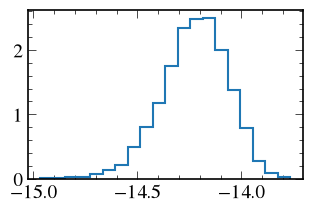

In [35]:
plt.hist(gen_samps[:, 272], **hist_settings)
plt.show()

In [34]:
np.savez_compressed('/data/taylor_group/Nima/AtlasNG20/notebooks/NG20_VanillaNoise.npz', **mcmc_fixed.get_samples())

In [ ]:
def red_samples(mcmc):
    s = np.asarray(mcmc.get_samples()['red_noise'])
    return {n: s[:, i] for i, n in enumerate(param_names)}

post_fixed, post_idx = red_samples(mcmc_fixed), red_samples(mcmc_idx)
chi = np.asarray(mcmc_idx.get_samples()['chrom_gp_index'])

fig, axes = plt.subplots(len(psrs), 4, figsize=(13, 2.2 * len(psrs)), squeeze=False)
for i, n in enumerate(names):
    for ax, key in zip(axes[i, :3], [f'{n}_chrom_log10_A', f'{n}_chrom_gamma', f'{n}_sw_log10_amp']):
        ax.hist(post_fixed[key], **hist_settings, label=r'$\chi=4$ fixed')
        ax.hist(post_idx[key], **hist_settings, label=r'$\chi$ sampled')
        ax.set_xlabel(key.replace(n + '_', ''))
    axes[i, 3].hist(chi[:, i], **hist_settings, color='C1')
    axes[i, 3].set_xlabel(r'$\chi$ (chrom_gp_index)')
    axes[i, 0].set_ylabel(n)
axes[0, 0].legend(fontsize=7)
plt.tight_layout()

In [ ]:
gw = {k: post_idx[k] for k in ('gwb_log10_A', 'gwb_gamma')}
plt.hist(post_fixed['gwb_log10_A'], **hist_settings, label=r'$\chi$ fixed')
plt.hist(gw['gwb_log10_A'], **hist_settings, label=r'$\chi$ sampled')
plt.xlabel(r'$\log_{10} A_\mathrm{GWB}$'); plt.legend()